# Part 3: Reward-Guided Fine-Tuning: A Controlled Study

**Question:** does a flow-matching policy improve when its better-performing experience receives a larger
weight in the flow-matching loss?

* **A**: the Part 2 checkpoint, frozen.
* **B**: A + fine-tuning on the collected chunks with all weights 1 (β = 0), plus demonstration replay.
* **C**: A + fine-tuning on the *same* collected chunks with $w_j\propto\min(e^{\beta R_{e(j)}},5)$, β = 2, plus the
  same replay, the same budget, the same minibatch indices, noise and flow times.

C − B isolates the weighting; C − A also includes the new data and the extra training.

## 1. Setup and the frozen Part 2 checkpoint

In [1]:
import json, time, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import Image as ShowImage, display

from pusht_ac.data import Normalizer, PushtChunkDataset, download_pusht, load_pusht_zarr
from pusht_ac.model import load_policy, save_policy
from pusht_ac.train import finetune_flow, reward_weights, dataset_loss
from pusht_ac.evaluation import VAL_SEEDS, TEST_SEEDS, COLLECT_SEEDS, evaluate, summarize, rollout, save_gif, make_env
from pusht_ac.stats import paired_summary
from pusht_ac import viz
from pusht_ac.viz import PAL

torch.set_num_threads(4)
RES, CKPT = Path('results_part3'), Path('checkpoints')
RES.mkdir(exist_ok=True)
sha = hashlib.sha256(open(CKPT / 'flow_policy.pt', 'rb').read()).hexdigest()
assert sha == Path('results_part2/flow_checkpoint_sha256.txt').read_text(), 'Part 2 checkpoint changed'
policy_A = load_policy(CKPT / 'flow_policy.pt')
normalizer = Normalizer.load(CKPT / 'normalizer.json')          # frozen Part 1/2 statistics, never refit
K, N = policy_A.chunk_size, 10
states, actions, episode_ends = load_pusht_zarr(download_pusht(Path('data')))
split = json.load(open(CKPT / 'split.json'))
demo_ds = PushtChunkDataset(states, actions, episode_ends, K, normalizer, split['train_episodes'])
val_ds = PushtChunkDataset(states, actions, episode_ends, K, normalizer, split['val_episodes'])
CFG = dict(beta=2.0, cap=5.0, mix=0.5, lr=1e-4, batch_new=64, batch_demo=64, default_updates=300,
           budget_candidates=[300, 1000, 3000], finetune_seeds=[0, 1, 2], K=K, N=N,
           collection_reset_seeds='2000-2024', collection_policy_seed='50000 + 2*(reset_seed-2000) + j, j in {0,1}',
           test_reset_seeds='1000-1099', test_policy_seed='reset_seed + offset (offset 0 primary; 10000, 20000 repeats)',
           part2_checkpoint_sha256=sha)
json.dump(CFG, open(RES / 'config.json', 'w'), indent=2)
print('Part 2 checkpoint verified unchanged:', sha[:16], '…')

Part 2 checkpoint verified unchanged: 319c4e455c89da57 …


## 2. Task 1: Collect rollouts with the unchanged Part 2 policy

25 collection reset seeds (2000–2024, disjoint from validation 0–49 and test 1000–1099) × 2 recorded policy-noise
seeds = 50 episodes, no rendering, $K=8$, $N=10$, standard 300-step limit. At every query the *starting
observation* and the *executed* (denormalized, clipped) actions are saved. The incomplete final chunk of an
episode is dropped from the dataset, but its rewards count toward $R_e=\max_t r_{e,t}$.

In [2]:
t0 = time.perf_counter()
env = make_env()
episodes, rows = [], []
for s in COLLECT_SEEDS:
    for j in range(2):
        ps = 50_000 + 2 * (s - COLLECT_SEEDS[0]) + j
        e = rollout(policy_A, normalizer, s, ps, num_steps=N, env=env, record=True)
        eid = len(episodes)
        episodes.append({'episode_id': eid, 'reset_seed': s, 'policy_seed': ps, 'score': e.max_reward, 'success': e.success,
                         'length': e.length, 'queries': len(e.queries), 'complete_chunks': sum(q[2] for q in e.queries),
                         'rewards': e.rewards})
        for qn, (o, acts, complete) in enumerate(e.queries):
            if complete:
                rows.append({'episode_id': eid, 'query': qn, 'obs': o, 'actions': acts, 'score': e.max_reward})
env.close()
collect_time = time.perf_counter() - t0
ep_df = pd.DataFrame(episodes)
ep_df.drop(columns='rewards').to_csv(RES / 'collection_episodes.csv', index=False)
obs_raw = np.stack([r['obs'] for r in rows]).astype(np.float32)
act_raw = np.stack([r['actions'] for r in rows]).astype(np.float32)
R = np.array([r['score'] for r in rows]); eid = np.array([r['episode_id'] for r in rows])
np.savez(RES / 'collection_dataset.npz', obs_raw=obs_raw, actions_raw=act_raw, episode_score=R, episode_id=eid,
         query_index=np.array([r['query'] for r in rows]),
         reset_seed=ep_df.reset_seed.values[eid], policy_seed=ep_df.policy_seed.values[eid])
coll = {'episodes': len(ep_df), 'retained_chunks': len(rows), 'policy_queries': int(ep_df.queries.sum()),
        'dropped_incomplete_chunks': int((ep_df.queries - ep_df.complete_chunks).sum()),
        'env_steps': int(ep_df.length.sum()), 'collection_time_s': collect_time,
        'score_mean': ep_df.score.mean(), 'score_std': ep_df.score.std(), 'score_min': ep_df.score.min(),
        'score_median': ep_df.score.median(), 'score_max': ep_df.score.max(), 'success_rate': ep_df.success.mean(),
        'same_seed_score_gap_mean': ep_df.groupby('reset_seed').score.agg(lambda x: abs(x.iloc[0] - x.iloc[1])).mean()}
json.dump(coll, open(RES / 'collection_summary.json', 'w'), indent=2, default=float)
pd.Series(coll).round(3).to_frame('collection')

,collection
episodes,50.000
retained_chunks,1663.000
policy_queries,1710.000
dropped_incomplete_chunks,47.000
env_steps,13483.000
collection_time_s,6.487
score_mean,0.920
score_std,0.163
score_min,0.074
score_median,0.973


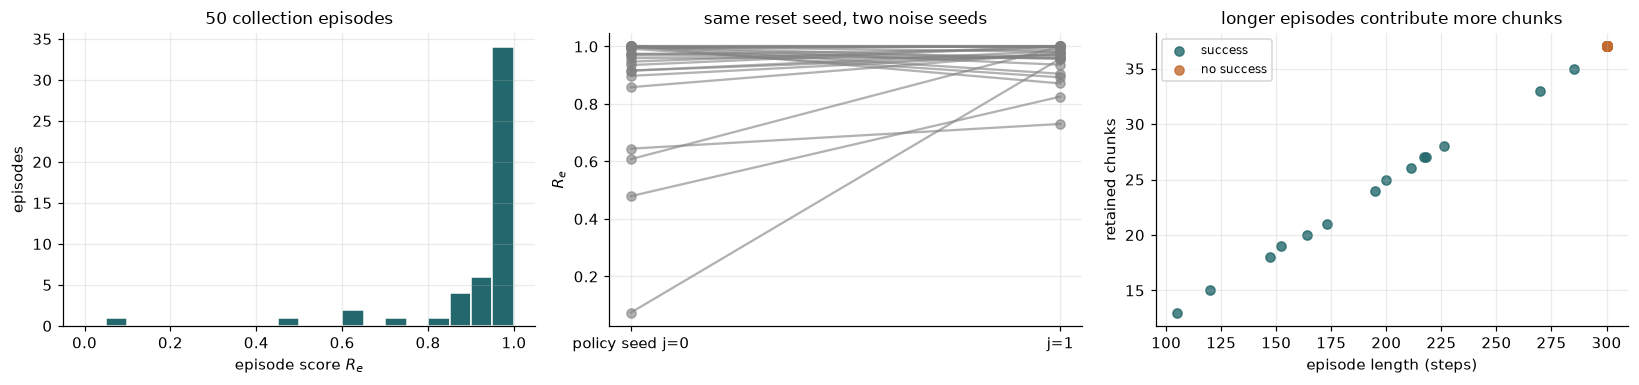

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].hist(ep_df.score, bins=np.linspace(0, 1, 21), color=PAL['flow'], edgecolor='white')
axes[0].set_xlabel('episode score $R_e$'); axes[0].set_ylabel('episodes'); axes[0].set_title('50 collection episodes')
pv = ep_df.assign(j=ep_df.groupby('reset_seed').cumcount()).pivot(index='reset_seed', columns='j', values='score')
for s_, (a_, b_) in pv.iterrows():
    axes[1].plot([0, 1], [a_, b_], 'o-', color='0.5', alpha=0.6)
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(['policy seed j=0', 'j=1']); axes[1].set_ylabel('$R_e$')
axes[1].set_title('same reset seed, two noise seeds')
for ok, col, lab in ((True, PAL['C'], 'success'), (False, PAL['mse'], 'no success')):
    sel = ep_df.success == ok
    axes[2].scatter(ep_df.length[sel], ep_df.complete_chunks[sel], color=col, label=lab, alpha=0.8)
axes[2].legend(fontsize=8)
axes[2].set_xlabel('episode length (steps)'); axes[2].set_ylabel('retained chunks'); axes[2].set_title('longer episodes contribute more chunks')
plt.tight_layout(); plt.savefig(RES / 'collection.png', bbox_inches='tight'); plt.show()

### Tracing one saved observation–chunk pair to its episode score

In [4]:
j0 = int(np.argmax(R)) if R.max() > R.min() else 0
e0 = episodes[eid[j0]]
q0 = rows[j0]['query']
print(f"tuple #{j0}: episode_id {eid[j0]}, reset seed {e0['reset_seed']}, policy seed {e0['policy_seed']}, query {q0}")
print('starting observation (raw):', np.round(obs_raw[j0], 2))
print('executed actions (raw, clipped):\n', np.round(act_raw[j0], 1))
seg = e0['rewards'][q0 * K:(q0 + 1) * K]
print('rewards while this chunk ran:', np.round(seg, 3))
print(f"episode rewards: {len(e0['rewards'])} steps, max {max(e0['rewards']):.3f} at step {int(np.argmax(e0['rewards']))}"
      f" -> attached score R = {R[j0]:.3f} (sum would be {sum(e0['rewards']):.1f})")

tuple #37: episode_id 1, reset seed 2000, policy seed 50001, query 0
starting observation (raw): [144.   280.   152.39 385.35   3.31]
executed actions (raw, clipped):
 [[132.2 283.3]
 [124.4 285. ]
 [119.5 297.5]
 [115.9 304.5]
 [115.4 314.9]
 [111.9 323.6]
 [109.8 330.8]
 [108.5 337.5]]
rewards while this chunk ran: [0.051 0.051 0.051 0.051 0.051 0.051 0.051 0.051]
episode rewards: 164 steps, max 1.000 at step 163 -> attached score R = 1.000 (sum would be 27.4)


## 3. Task 2: Weights and fine-tuning

$u_j=\min\{e^{\beta R_{e(j)}},5\}$, $w_j=u_j/\overline{u}$ with β = 2, computed once over all retained chunks.
The collected raw observations and executed actions are normalized with the frozen Part 2 statistics.

example: R=0.8 -> 4.953  R=0.2 -> 1.492


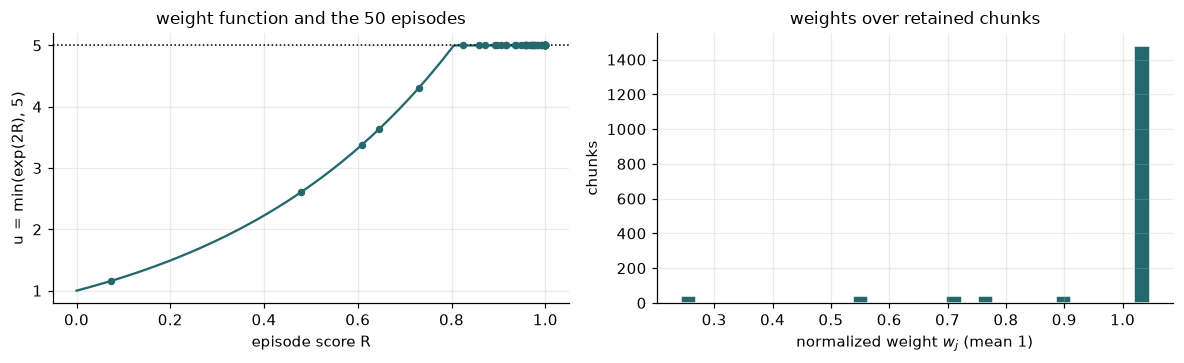

,weights
M,1663
mean_w,1.0
min_w,0.242706
max_w,1.046169
fraction_capped,0.888755
kish_effective_sample_size,1626.133864
no_weighting_signal,False
share_of_chunks_from_successful_episodes,0.199038
share_of_weight_from_successful_episodes,0.208227
share_of_chunks_with_R>=0.9,0.777511


In [5]:
new_obs = torch.as_tensor(normalizer.normalize_state(obs_raw), dtype=torch.float32)
new_chunks = torch.as_tensor(normalizer.normalize_action(act_raw), dtype=torch.float32)
u, w = reward_weights(R, CFG['beta'], CFG['cap'])
w_equal = np.ones_like(w)
no_signal = np.allclose(u, u[0])
print('example: R=0.8 ->', round(min(np.exp(2 * 0.8), 5), 3), ' R=0.2 ->', round(np.exp(2 * 0.2), 3))
wstats = {'M': len(w), 'mean_w': w.mean(), 'min_w': w.min(), 'max_w': w.max(), 'fraction_capped': float((u >= 5 - 1e-9).mean()),
          'kish_effective_sample_size': float(w.sum() ** 2 / (w ** 2).sum()), 'no_weighting_signal': bool(no_signal),
          'share_of_chunks_from_successful_episodes': float(ep_df.success.values[eid].mean()),
          'share_of_weight_from_successful_episodes': float((w * ep_df.success.values[eid]).sum() / w.sum()),
          'share_of_chunks_with_R>=0.9': float((R >= 0.9).mean()),
          'share_of_weight_with_R>=0.9': float(w[R >= 0.9].sum() / w.sum())}
json.dump(wstats, open(RES / 'weights_summary.json', 'w'), indent=2)
if no_signal:
    print('All unnormalized weights are equal: the collection gives NO weighting signal; C would equal B.')
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
rr = np.linspace(0, 1, 200)
axes[0].plot(rr, np.minimum(np.exp(2 * rr), 5), color=PAL['C']); axes[0].axhline(5, color='k', ls=':', lw=1)
axes[0].scatter(ep_df.score, np.minimum(np.exp(2 * ep_df.score), 5), color=PAL['C'], s=15, zorder=3)
axes[0].set_xlabel('episode score R'); axes[0].set_ylabel('u = min(exp(2R), 5)'); axes[0].set_title('weight function and the 50 episodes')
axes[1].hist(w, bins=30, color=PAL['C'], edgecolor='white'); axes[1].set_xlabel('normalized weight $w_j$ (mean 1)'); axes[1].set_ylabel('chunks')
axes[1].set_title('weights over retained chunks')
plt.tight_layout(); plt.savefig(RES / 'weights.png', bbox_inches='tight'); plt.show()
pd.Series(wstats).to_frame('weights')

### Budget check on validation only
The default is 300 updates. For each fine-tuning seed, B and C are also run for 1000 and 3000 updates (same
generator, so the first 300 updates are identical) and rolled out on validation seeds 0–49. The budget with the
highest validation score averaged over B and C and the three seeds is used for **both** branches.

In [6]:
ft_kw = dict(lr=CFG['lr'], batch_new=CFG['batch_new'], batch_demo=CFG['batch_demo'], mix=CFG['mix'])
t_budget = time.perf_counter()
val_A = summarize(evaluate(policy_A, normalizer, VAL_SEEDS)[0])['score_mean']
brows = []
for U in CFG['budget_candidates']:
    for seed in CFG['finetune_seeds']:
        for branch, ww in (('B', w_equal), ('C', w)):
            p, _, _, _ = finetune_flow(policy_A, new_obs, new_chunks, ww, demo_ds, updates=U, seed=seed, **ft_kw)
            vdf, _ = evaluate(p, normalizer, VAL_SEEDS)
            brows.append({'updates': U, 'seed': seed, 'branch': branch, 'val_score': vdf.max_reward.mean(), 'val_success': vdf.success.mean()})
t_budget = time.perf_counter() - t_budget
budget = pd.DataFrame(brows); budget.to_csv(RES / 'budget_validation.csv', index=False)
btab = budget.pivot_table(index='updates', columns='branch', values=['val_score', 'val_success'])
btab[('mean_B_C_score', '')] = btab['val_score'].mean(axis=1)
UPDATES = int(btab[('mean_B_C_score', '')].idxmax())
CFG['chosen_updates'] = UPDATES; json.dump(CFG, open(RES / 'config.json', 'w'), indent=2)
print(f'validation score of A: {val_A:.3f};  chosen budget (validation): {UPDATES} updates')
btab.round(3)

validation score of A: 0.888;  chosen budget (validation): 300 updates


val_score        val_success        mean_B_C_score
branch          B      C           B      C               
updates                                                   
300         0.876  0.879       0.280  0.200          0.878
1000        0.829  0.825       0.193  0.273          0.827
3000        0.834  0.841       0.247  0.227          0.838

### Fine-tune B and C with the chosen budget (3 fine-tuning seeds)
Each branch: fresh copy of A, fresh Adam (lr 1e-4), minibatches of 64 collected + 64 demonstration chunks,
$\mathcal L_b=0.5\,\mathcal L_{new,b}+0.5\,\mathcal L_{demo}$ with the weight applied to each chunk's own error.
B and C with the same seed draw identical indices, $\epsilon$ and $\tau$; only $w$ differs.

In [7]:
models, ft_logs, ft_time = {}, [], {}
for seed in CFG['finetune_seeds']:
    for branch, ww in (('B', w_equal), ('C', w)):
        p, lg, _, inf = finetune_flow(policy_A, new_obs, new_chunks, ww, demo_ds, updates=UPDATES, seed=seed, val_ds=val_ds, **ft_kw)
        models[(branch, seed)] = p
        save_policy(p, CKPT / f'flow_{branch}_seed{seed}.pt', branch=branch, finetune_seed=seed, updates=UPDATES, beta=0 if branch == 'B' else CFG['beta'])
        lg['branch'], lg['seed'] = branch, seed
        ft_logs.append(lg); ft_time[f'{branch}_seed{seed}'] = inf['finetune_time_s']
ft_log = pd.concat(ft_logs); ft_log.to_csv(RES / 'finetune_logs.csv', index=False)
json.dump(ft_time, open(RES / 'finetune_time.json', 'w'), indent=2)
print('fine-tuning time per branch (s):', {k_: round(v, 1) for k_, v in ft_time.items()})
print('validation-demo FM loss of A:', round(dataset_loss(policy_A, val_ds.obs, val_ds.chunks), 4))

fine-tuning time per branch (s): {'B_seed0': 0.9, 'C_seed0': 0.7, 'B_seed1': 0.5, 'C_seed1': 0.5, 'B_seed2': 0.6, 'C_seed2': 0.6}
validation-demo FM loss of A: 0.2484


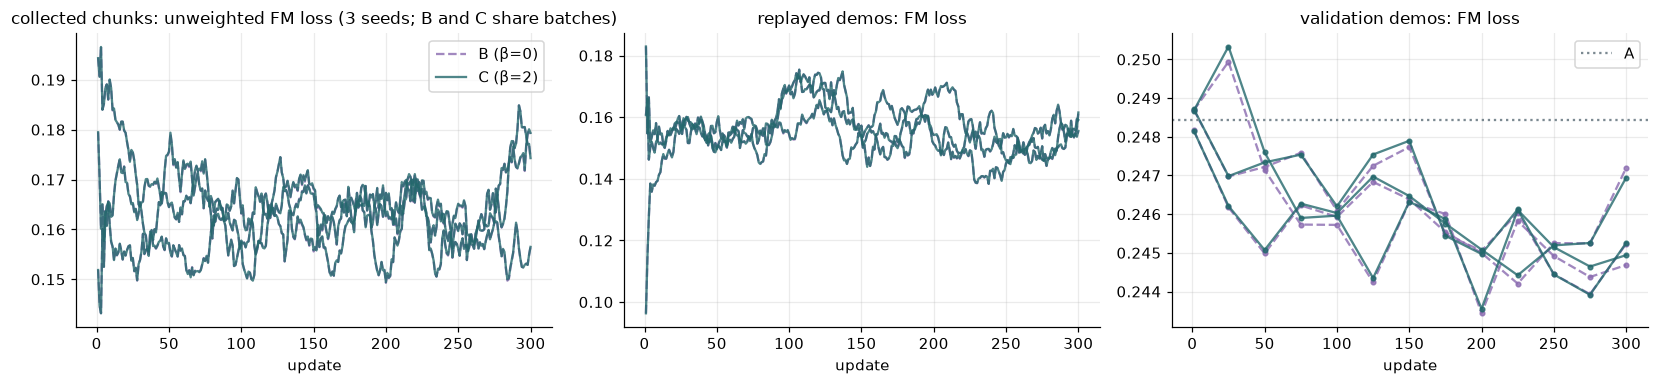

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for (branch, seed), lg in ft_log.groupby(['branch', 'seed']):
    sm = lg.select_dtypes('number').rolling(20, min_periods=1).mean()
    ls = '--' if branch == 'B' else '-'
    axes[0].plot(lg.step, sm.loss_new_unweighted, ls, color=PAL[branch], alpha=0.8, label=f'{branch} (β={0 if branch == "B" else 2})' if seed == 0 else None)
    axes[1].plot(lg.step, sm.loss_demo, ls, color=PAL[branch], alpha=0.8)
    v = lg.dropna(subset=['val_demo_loss']); axes[2].plot(v.step, v.val_demo_loss, 'o' + ls, ms=3, color=PAL[branch], alpha=0.8)
axes[2].axhline(dataset_loss(policy_A, val_ds.obs, val_ds.chunks), color=PAL['A'], ls=':', label='A')
axes[0].set_title('collected chunks: unweighted FM loss (3 seeds; B and C share batches)'); axes[1].set_title('replayed demos: FM loss'); axes[2].set_title('validation demos: FM loss')
for a_ in axes: a_.set_xlabel('update')
axes[0].legend(); axes[2].legend()
plt.tight_layout(); plt.savefig(RES / 'finetune_losses.png', bbox_inches='tight'); plt.show()

## 4. Task 3: Compare A, B and C on the common test set

Reset seeds 1000–1099; policy-noise seed = reset seed for every condition (common random numbers), plus two
repeat passes with different policy-noise seeds.

In [9]:
conds = {('A', -1): policy_A, **models}
test_rows, per_ep = [], []
for off in (0, 10_000, 20_000):
    for (branch, seed), p in conds.items():
        df, _ = evaluate(p, normalizer, TEST_SEEDS, policy_seed_offset=off)
        df['branch'], df['ft_seed'], df['offset'] = branch, seed, off
        per_ep.append(df)
per_ep = pd.concat(per_ep, ignore_index=True); per_ep.to_csv(RES / 'test_episodes_ABC.csv', index=False)
prim = per_ep[per_ep.offset == 0]
tab = (prim.groupby(['branch', 'ft_seed']).agg(score_mean=('max_reward', 'mean'), score_std=('max_reward', 'std'),
       success_rate=('success', 'mean'), mean_length=('length', 'mean'), rollout_time_s=('total_time_s', 'sum')).reset_index())
tab.to_csv(RES / 'test_summary_ABC.csv', index=False)
tab.round(3)

,branch,ft_seed,score_mean,score_std,success_rate,mean_length,rollout_time_s
0,A,-1,0.840,0.265,0.22,280.75,10.315
1,B,0,0.815,0.299,0.22,279.99,10.442
2,B,1,0.782,0.330,0.14,287.93,9.509
3,B,2,0.804,0.305,0.16,284.64,10.292
4,C,0,0.801,0.305,0.21,279.70,10.307
5,C,1,0.766,0.337,0.19,280.65,10.474
6,C,2,0.794,0.319,0.14,284.60,9.184


In [10]:
def scores(branch, seed, off=0):
    d = per_ep[(per_ep.branch == branch) & (per_ep.ft_seed == seed) & (per_ep.offset == off)].sort_values('reset_seed')
    return d.max_reward.values, d.success.values.astype(float)

drows = []
for seed in CFG['finetune_seeds']:
    for name, (x, y) in {'C - B': (('B', seed), ('C', seed)), 'C - A': (('A', -1), ('C', seed)), 'B - A': (('A', -1), ('B', seed))}.items():
        sx, cx = scores(*x); sy, cy = scores(*y)
        ps = paired_summary(sx, sy); pc = paired_summary(cx, cy)
        drows.append({'ft_seed': seed, 'contrast': name, 'score diff': ps['mean_diff'], 'CI low': ps['ci_low'], 'CI high': ps['ci_high'],
                      'p (sign-flip)': ps['p_signflip'], 'wins/ties/losses': f"{ps['wins']}/{ps['ties']}/{ps['losses']}",
                      'success diff': pc['mean_diff']})
# pooled over fine-tuning seeds (average the three branch copies per test episode first)
for name, (x, y) in {'C - B': ('B', 'C'), 'C - A': ('A', 'C'), 'B - A': ('A', 'B')}.items():
    def avg(b):
        if b == 'A': return scores('A', -1)
        ss = [scores(b, s_) for s_ in CFG['finetune_seeds']]
        return np.mean([a_ for a_, _ in ss], 0), np.mean([c_ for _, c_ in ss], 0)
    (sx, cx), (sy, cy) = avg(x), avg(y)
    ps = paired_summary(sx, sy)
    drows.append({'ft_seed': 'mean of 3', 'contrast': name, 'score diff': ps['mean_diff'], 'CI low': ps['ci_low'], 'CI high': ps['ci_high'],
                  'p (sign-flip)': ps['p_signflip'], 'wins/ties/losses': f"{ps['wins']}/{ps['ties']}/{ps['losses']}",
                  'success diff': float((cy - cx).mean())})
diffs = pd.DataFrame(drows); diffs.to_csv(RES / 'test_contrasts.csv', index=False)
diffs.round(4)

,ft_seed,contrast,score diff,CI low,CI high,p (sign-flip),wins/ties/losses,success diff
0,0,C - B,-0.0133,-0.0543,0.0265,0.5289,38/15/47,-0.0100
1,0,C - A,-0.0389,-0.0853,0.0074,0.1076,39/5/56,-0.0100
2,0,B - A,-0.0256,-0.0770,0.0262,0.3355,42/8/50,0.0000
3,1,C - B,-0.0164,-0.0604,0.0259,0.4648,44/11/45,0.0500
4,1,C - A,-0.0745,-0.1304,-0.0223,0.0085,36/5/59,-0.0300
5,1,B - A,-0.0581,-0.1161,-0.0026,0.0476,37/9/54,-0.0800
6,2,C - B,-0.0100,-0.0437,0.0219,0.5632,42/11/47,-0.0200
7,2,C - A,-0.0465,-0.1014,0.0045,0.0910,41/6/53,-0.0800
8,2,B - A,-0.0365,-0.0852,0.0088,0.1347,45/4/51,-0.0600
9,mean of 3,C - B,-0.0132,-0.0370,0.0099,0.2697,49/2/49,0.0067


### Robustness: all three policy-noise passes (300 episodes per condition and seed)

In [11]:
rob = (per_ep.groupby(['branch', 'ft_seed']).agg(score_mean=('max_reward', 'mean'), success_rate=('success', 'mean'), episodes=('max_reward', 'size')).reset_index())
by_off = per_ep.groupby(['branch', 'offset']).max_reward.mean().unstack().round(3)
rob.to_csv(RES / 'test_summary_ABC_all_offsets.csv', index=False)
display(rob.round(3)); display(by_off)

,branch,ft_seed,score_mean,success_rate,episodes
0,A,-1,0.849,0.230,300
1,B,0,0.830,0.247,300
2,B,1,0.832,0.187,300
3,B,2,0.832,0.207,300
4,C,0,0.820,0.217,300
5,C,1,0.831,0.233,300
6,C,2,0.818,0.203,300


offset,0,10000,20000
branch,,,
A,0.840,0.837,0.870
B,0.800,0.840,0.854
C,0.787,0.834,0.849


### Costs

In [12]:
costs = {'collection: episodes': coll['episodes'], 'collection: env steps': coll['env_steps'],
         'collection: wall time (s)': round(coll['collection_time_s'], 1),
         'fine-tuning: updates per branch': UPDATES,
         'fine-tuning: mean time per branch (s)': round(np.mean(list(ft_time.values())), 2),
         'fine-tuning: total for 6 branches (s)': round(sum(ft_time.values()), 1),
         'budget check on validation, incl. 900 val. episodes (s)': round(t_budget, 1), 'Part 2 training time (s)': round(json.load(open('results_part2/flow_train_info.json'))['train_time_s'], 1)}
json.dump(costs, open(RES / 'costs.json', 'w'), indent=2)
pd.Series(costs).to_frame('cost')

,cost
collection: episodes,50.00
collection: env steps,13483.00
collection: wall time (s),6.50
fine-tuning: updates per branch,300.00
fine-tuning: mean time per branch (s),0.63
fine-tuning: total for 6 branches (s),3.80
"budget check on validation, incl. 900 val. episodes (s)",138.70
Part 2 training time (s),193.50


### Where do C and B differ? Per-seed changes and initial-state difficulty

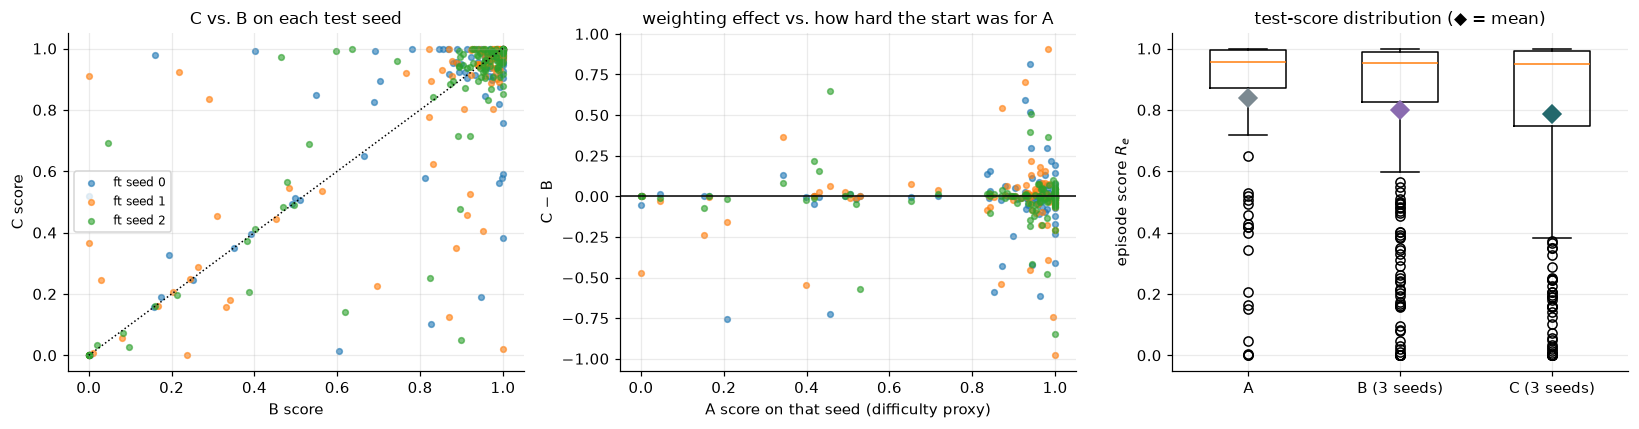

In [13]:
sA, _ = scores('A', -1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for seed in CFG['finetune_seeds']:
    sB, _ = scores('B', seed); sC, _ = scores('C', seed)
    axes[0].scatter(sB, sC, s=14, alpha=0.6, label=f'ft seed {seed}')
    axes[1].scatter(sA, sC - sB, s=14, alpha=0.6)
axes[0].plot([0, 1], [0, 1], 'k:', lw=1); axes[0].set_xlabel('B score'); axes[0].set_ylabel('C score'); axes[0].legend(fontsize=8)
axes[0].set_title('C vs. B on each test seed')
axes[1].axhline(0, color='k', lw=1); axes[1].set_xlabel('A score on that seed (difficulty proxy)'); axes[1].set_ylabel('C − B')
axes[1].set_title('weighting effect vs. how hard the start was for A')
m = prim.groupby('branch').max_reward
axes[2].boxplot([prim[prim.branch == b].max_reward for b in 'ABC'], tick_labels=['A', 'B (3 seeds)', 'C (3 seeds)'], widths=0.5)
for i, b in enumerate('ABC'):
    axes[2].plot(i + 1, prim[prim.branch == b].max_reward.mean(), 'D', color=PAL[b], ms=8)
axes[2].set_ylabel('episode score $R_e$'); axes[2].set_title('test-score distribution (◆ = mean)')
plt.tight_layout(); plt.savefig(RES / 'abc_comparison.png', bbox_inches='tight'); plt.show()

### How far did fine-tuning move the policy?
Mean distance (pixels) between chunks sampled by A and by B / C from the same validation observations and the
**same** initial noise $Z_0$. This shows how strongly each update changed behaviour, independent of the simulator.

In [14]:
gq = torch.Generator().manual_seed(99)
idx = torch.randint(len(val_ds), (2000,), generator=gq)
z0 = torch.randn((2000, K, 2), generator=gq)
with torch.no_grad():
    ref = normalizer.denormalize_action(policy_A.sample_actions(val_ds.obs[idx], z0=z0).numpy())
    shift = {f'{b} seed {s_}': float(np.linalg.norm(normalizer.denormalize_action(p.sample_actions(val_ds.obs[idx], z0=z0).numpy()) - ref, axis=-1).mean())
             for (b, s_), p in models.items()}
    shift_BC = {f'C vs B seed {s_}': float(np.linalg.norm(normalizer.denormalize_action(models[('C', s_)].sample_actions(val_ds.obs[idx], z0=z0).numpy())
                - normalizer.denormalize_action(models[('B', s_)].sample_actions(val_ds.obs[idx], z0=z0).numpy()), axis=-1).mean()) for s_ in CFG['finetune_seeds']}
json.dump({**shift, **shift_BC}, open(RES / 'policy_shift_px.json', 'w'), indent=2)
pd.Series({**shift, **shift_BC}).round(2).to_frame('mean |Δ action| (px), same noise')

,"mean |Δ action| (px), same noise"
B seed 0,5.22
C seed 0,5.28
B seed 1,5.00
C seed 1,5.06
B seed 2,5.01
C seed 2,5.05
C vs B seed 0,0.54
C vs B seed 1,0.50
C vs B seed 2,0.51


### Representative rollouts (fine-tuning seed 0, same reset and noise seeds for A, B and C)
The seeds with the largest C − B gain and the largest C − B loss, plus the shared illustration seed 1100.

In [15]:
sB0, _ = scores('B', 0); sC0, _ = scores('C', 0)
d0 = sC0 - sB0
picks = {'gain': TEST_SEEDS[int(np.argmax(d0))], 'loss': TEST_SEEDS[int(np.argmin(d0))], 'seed1100': 1100}
gif_info = {}
for name, seed in picks.items():
    for b, p in (('A', policy_A), ('B', models[('B', 0)]), ('C', models[('C', 0)])):
        e = rollout(p, normalizer, seed, seed, render=True)
        save_gif(e.frames, RES / f'{b}_{name}.gif')
        gif_info[f'{b}_{name}'] = {'reset_seed': seed, 'score': e.max_reward, 'success': e.success, 'length': e.length}
json.dump(gif_info, open(RES / 'gif_info.json', 'w'), indent=2)
pd.DataFrame(gif_info).T

,reset_seed,score,success,length
A_gain,1082,0.940158,False,300
B_gain,1082,0.160902,False,300
C_gain,1082,0.977981,False,300
A_loss,1083,0.206687,False,300
B_loss,1083,0.946529,False,300
C_loss,1083,0.189295,False,300
A_seed1100,1100,0.976559,False,300
B_seed1100,1100,0.98402,False,300
C_seed1100,1100,1.0,True,264


## 5. Findings (Part 3)

**Collection** (A unchanged, 25 reset seeds × 2 noise seeds): 50 episodes, 13,483 environment steps, 1,710 policy
queries. 1,663 complete chunks were retained and 47 incomplete final chunks dropped; collection took 6.5 s. Episode
scores: mean 0.920 ± 0.163, median 0.973, minimum 0.074, success 28%. The two noise seeds on the same reset seed
differ by 0.106 on average, so sampling noise alone moves an episode's score substantially.

**Credit assignment, traced.** Tuple #37 (episode 1, reset seed 2000, policy seed 50001, first query) moved the
pusher toward the T while the reward stayed at 0.051 for all 8 steps. Its attached score is $R=1.0$ because the
episode reached full coverage at step 163. The same score goes to every chunk in that episode, useful or not.

**Weights.** β = 2 with cap 5 saturates at $R\ge \tfrac12\ln 5\approx0.805$. Only 5 of 50 collection episodes fall
below that (scores 0.07, 0.48, 0.61, 0.65, 0.73), so **89% of chunks share the maximum weight**. Normalized weights
range from 0.24 to 1.05, and the Kish effective sample size is 1,626 of 1,663. The weighting signal exists
(`no_weighting_signal = False`), but it is weak. In practice it down-weights the chunks of 5 poor episodes and leaves
everything else equal. Successful episodes provide 19.9% of the chunks and 20.8% of the weight; truncated episodes
contribute 37 chunks each against ~24 for successful ones, so uniform chunk sampling leans toward long, failed episodes.

**Budget (validation only).** A scores 0.888 on validation seeds 0–49. B / C score 0.876 / 0.879 after 300
updates, 0.829 / 0.825 after 1000, and 0.834 / 0.841 after 3000 (mean over 3 fine-tuning seeds). The default of 300
updates was kept for both branches.

**Test results** (reset seeds 1000–1099, policy-noise seed = reset seed, 3 fine-tuning seeds):

| condition | score mean ± std | success |
|---|---|---|
| A: Part 2, frozen | 0.840 ± 0.265 | 22% |
| B: equal weights, seeds 0 / 1 / 2 | 0.815 / 0.782 / 0.804 (± ≈ 0.31) | 22 / 14 / 16% |
| C: reward weights, seeds 0 / 1 / 2 | 0.801 / 0.766 / 0.794 (± ≈ 0.32) | 21 / 19 / 14% |

Paired contrasts, averaging the three fine-tuned copies per test seed: **C − B = −0.013** (95% CI −0.037 to +0.010,
p = 0.27); **C − A = −0.053** (−0.096 to −0.012, p = 0.013); B − A = −0.040 (−0.082 to +0.002, p = 0.06). C − B is
slightly negative for every fine-tuning seed (−0.013, −0.016, −0.010), and none of the three is significant; the
success-rate differences are −1, +5 and −2 points. Over all three noise passes (300 episodes per condition and seed)
A = 0.849, B = 0.830–0.832 and C = 0.818–0.831, which tells the same story at a smaller scale.

**Costs.** Collection: 50 episodes, 6.5 s. Fine-tuning: 300 updates, ≈ 0.6 s per branch (3.8 s for all six). The
validation budget check took 139 s, almost all of it 900 validation episodes. For comparison, Part 2 training took
194 s.

**How much did the policy change?** With identical initial noise on 2,000 validation observations, B and C move
the executed actions by ≈ 5 px relative to A, while C differs from B by only ≈ 0.5 px. Yet the per-seed test scores
of B and C differ from A by 0.14 on average, and each branch has 9–15 seeds that drop by more than 0.3 and 5–7 that
gain more than 0.3. Contact-rich pushing is sensitive enough that a few pixels can flip an episode. The representative
GIFs show this: on seed 1082, A = 0.94, B = 0.16 and C = 0.98 (B pushes the T past the target and out to a corner); on
seed 1083, A = 0.21, B = 0.95 and C = 0.19. These are near-identical policies with opposite outcomes. On seed 1100, C
succeeds (264 steps) and A and B finish just short.

**Does the evidence support the hypothesis?** No. With this collection, β and cap, reward weighting did not improve
the policy: C − B is a small negative number with a confidence interval that includes zero. Fine-tuning on the
policy's own rollouts, weighted or not, slightly *hurt* compared with leaving A alone. Likely reasons:

1. *Saturated weights.* A was already good on the collection seeds (0.92 mean), so the capped exponential gives
   almost everyone the same weight. The experiment barely varies the quantity it is meant to test.
2. *Coarse credit.* Every chunk in an episode gets the episode's best moment, including the chunks after the best
   moment and the wandering before it. Most chunks in a "1.0" episode did nothing special.
3. *Self-generated data.* B and C regress onto A's own samples. They add no new behaviour, but they do sharpen A's
   distribution toward its own habits, including its mistakes, while using half of every batch that demonstrations
   would otherwise fill.
4. *Initial-state difficulty and luck.* The collection seeds were easier than the test seeds (A: 0.92 vs 0.84), and
   two noise seeds on the same start differ by 0.11 on average. An episode score mixes policy quality, start
   difficulty and chance; a max-over-time score also credits a brief lucky overlap.
5. *Episode length.* Failed episodes run to the 300-step limit and contribute ~37 chunks against ~24 for successes,
   which works against the weighting under uniform sampling.

These conclusions rest on one Part 2 checkpoint (one training seed), three fine-tuning seeds, and 100 test reset
seeds with three noise passes. The result is inconclusive-to-negative for reward weighting at this scale, not
evidence that reward-weighted flow matching cannot work. A collection with a wider spread of scores (harder start states,
or rank- or group-relative weights instead of a capped exponential) would be needed for a sharper test.